In [847]:
def creer_graphe(nb_sommet):
    graphe = {}
    for i in range(1, nb_sommet + 1):
        graphe[i] = []
    for i in range(1, nb_sommet + 1):
        nb_arretes = random.randint(0, nb_sommet - 1)
        for j in range(nb_arretes):
            voisin = random.randint(1, nb_sommet)
            if voisin != i and voisin not in graphe[i]:
              graphe[i].append(voisin)
              if i not in graphe[voisin]:
                graphe[voisin].append(i)
    return graphe

In [848]:
graphe1=creer_graphe(7)

In [849]:
import networkx as nx
import matplotlib.pyplot as plt

def dessiner_graphe(graphe):
    G = nx.Graph()

    for i, voisins in graphe.items():
        for v in voisins:
            G.add_edge(i, v)

    nx.draw(
        G,
        with_labels=True,
        node_color='skyblue',
        node_size=800,
        font_weight='bold',
        edge_color='gray'
    )

    plt.title("Visualisation du graphe de contacts")
    plt.show()


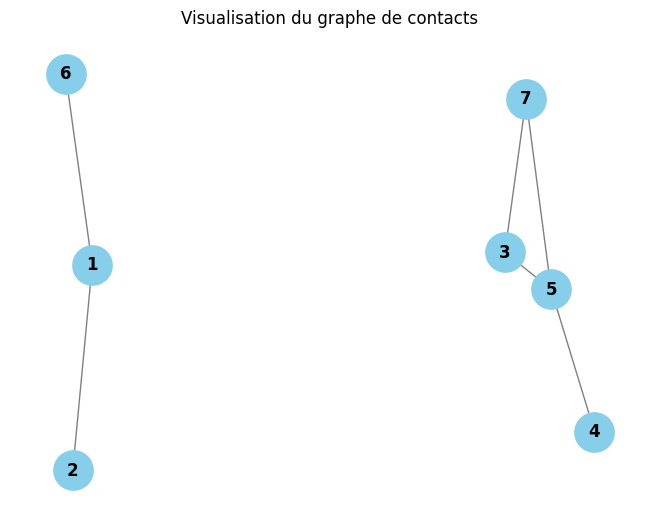

In [850]:
dessiner_graphe(graphe1)

In [851]:
def personnes_a_risque(graphe, A):
    pile = [A]
    visite = set()

    while pile:
        personne = pile.pop()
        if personne not in visite:
            visite.add(personne)
            pile.extend(graphe[personne])

    return visite


In [852]:
print(personnes_a_risque(graphe1, 1))

{1, 2, 6}


In [858]:
def verifier_risque(graphe, personne_infectee, personne_a_verifier):
    pile = [personne_infectee]
    visite = set()
    while pile:
        personne = pile.pop()
        if personne == personne_a_verifier:
            return True
        if personne not in visite:
            visite.add(personne)
            pile.extend(graphe[personne])
    return False

In [857]:
print(verifier_risque(graphe1, 1,5))

False


In [875]:
def nombre_personnes_a_risque(graphe, personne_infectee):
    personnes_risque = personnes_a_risque(graphe, personne_infectee)
    return len(personnes_risque)


In [876]:
print(nombre_personnes_a_risque(graphe1, 3))


4


In [869]:
def est_foyer_epidemique(graphe, personne_infectee):
    total_personnes = len(graphe)
    return nombre_personnes_a_risque(graphe, personne_infectee) == total_personnes


In [870]:
est_foyer_epidemique(graphe1, 1)

False

In [880]:
def personne_saine(graphe, personne_infectee):
    return set(graphe) - personnes_a_risque(graphe, personne_infectee)



In [878]:
personne_saine(graphe1, 1)

{3, 4, 5, 7}